# NPUWattch hands-on — 2. PyTorchSim: more workloads on the TPU-like NPU

Notebook 1 ran one matmul. This notebook runs the other PyTorchSim workloads
of the tutorial on the same TPUv3-like NPU (two 128×128 systolic arrays, 128
VPU lanes, 16 MB VMEM, 16 HBM2 channels). All runs are float32, because
PyTorchSim simulates float32 kernels only.

The point of each section is not the number but the reason for it. For every
workload we ask three questions: which part of the hardware does the work,
which simulator counter NPUWattch charges it from, and where in the report
you can see it.

```
pytorchsim/tpu_like_fp32/
├── compound_components.yaml, projection.yaml, user_components.yaml   the hardware model (shared)
├── matmul_1024/                       the 1024^3 matmul of notebook 1
├── matmul_train/                      forward + backward of the 1024^3 matmul (3 kernels)
├── matmul_2048_1core/                 one 2048^3 matmul on 1 core
├── matmul_2048_2core/                 the same matmul on 2 cores (a different PyTorchSim config)
├── softmax/                           softmax and exp2 on a 1024×1024 tensor: no MAC at all
├── resnet50/                          the 7 ResNet-50 layers of the Timeloop example, plus ReLU and batch norm
├── llama3_8b/{prefill,decode}/        one Llama-3-8B decoder block, T=512 and T=1
├── gemma2_9b/{prefill,decode}/        one Gemma-2-9B decoder block
└── deepseek_v2_lite/{prefill,decode}/ one DeepSeek-V2-Lite MoE decoder block
```

Each workload folder is one PyTorchSim run root: `config.yml`,
`togsim_results/`, `outputs/`, `booksim2_config/`, and `kernels.yaml`, which
names the kernels. Its `run` script points at the hardware model in the
design folder with `--compound-components ../compound_components.yaml` and
the two other definition flags. `how_the_data_was_made/` holds the PyTorch
script and the run manifest.

In [3]:
import sys; sys.path.insert(0, ".")
from tutorial_helpers import *
import pandas as pd, re
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
print("npuwattch:", npuwattch_binary())


def window_components(rep, label, top=8):
    """The per-component energy of one window, from report.json."""
    labels = [w["label"] for w in rep["windows"]]
    i = labels.index(label)
    rows = [{"component": r["name"], "energy": r["cells"][i]}
            for r in rep["matrix"]["rows"] if r["cells"][i] != "—"]
    return pd.DataFrame(rows).head(top)


def occupancy_table(text, names):
    """The useful MACs and the active PE cycles of each GEMM kernel (NW-6222), with its name."""
    rows = []
    for _, code_, line in messages(text):
        if code_ != "NW-6222":
            continue
        m = re.search(r": (\w+): (\d+) useful MACs of (\d+) active PE cycles \(([\d.]+)%\)", line)
        rows.append({"kernel": names.get(m.group(1), m.group(1)), "useful MACs": int(m.group(2)),
                     "active PE cycles": int(m.group(3)), "occupancy %": float(m.group(4))})
    return pd.DataFrame(rows)


def kernel_names(example_dir):
    """hash -> name from kernels.yaml (the first name of each hash)."""
    names = {}
    for line in (example_dir / "kernels.yaml").read_text().splitlines():
        m = re.search(r"name: ([^,]+), hash: (\w+)", line)
        if m and m.group(2) not in names:
            names[m.group(2)] = m.group(1)
    return names

npuwattch: /home/KNUEEhdd1/ys_knu/kmk/miniforge3/envs/npuwattch/bin/npuwattch


## 1. Run them all

Each run takes a few seconds. We keep the console text and the report of
each run.

In [ ]:
WORKLOADS = {
    "matmul 1024³ (nb 1)":      "pytorchsim/tpu_like_fp32/matmul_1024",
    "matmul train":             "pytorchsim/tpu_like_fp32/matmul_train",
    "matmul 2048³ 1 core":      "pytorchsim/tpu_like_fp32/matmul_2048_1core",
    "matmul 2048³ 2 cores":     "pytorchsim/tpu_like_fp32/matmul_2048_2core",
    "softmax + exp2":           "pytorchsim/tpu_like_fp32/softmax",
    "ResNet-50":                "pytorchsim/tpu_like_fp32/resnet50",
    "Llama-3-8B prefill":       "pytorchsim/tpu_like_fp32/llama3_8b/prefill",
    "Llama-3-8B decode":        "pytorchsim/tpu_like_fp32/llama3_8b/decode",
    "Gemma-2-9B prefill":       "pytorchsim/tpu_like_fp32/gemma2_9b/prefill",
    "Gemma-2-9B decode":        "pytorchsim/tpu_like_fp32/gemma2_9b/decode",
    "DeepSeek-V2-Lite prefill": "pytorchsim/tpu_like_fp32/deepseek_v2_lite/prefill",
    "DeepSeek-V2-Lite decode":  "pytorchsim/tpu_like_fp32/deepseek_v2_lite/decode",
}
texts, reps = {}, {}
for label, path in WORKLOADS.items():
    if not (example(path) / "run").exists():
        print(f"{label:28s} (folder not present, skipped)")
        continue
    texts[label] = run(example(path))
    reps[label] = report(example(path))
    print(f"{label:28s} {reps[label]['totals']['energy_str']:>12s}   {len(reps[label]['windows']):2d} windows")

matmul 1024³ (nb 1)           6.14e+03 µJ    1 windows
matmul train                  1.85e+04 µJ    3 windows
matmul 2048³ 1 core           4.91e+04 µJ    1 windows
matmul 2048³ 2 cores          4.88e+04 µJ    1 windows
softmax + exp2                2.07e+03 µJ    4 windows
ResNet-50                     2.08e+04 µJ   19 windows
Llama-3-8B prefill            6.91e+05 µJ   13 windows
Llama-3-8B decode             4.42e+04 µJ   13 windows
Gemma-2-9B prefill            6.96e+05 µJ   13 windows
Gemma-2-9B decode             3.96e+04 µJ   13 windows
DeepSeek-V2-Lite prefill      3.49e+05 µJ   17 windows
DeepSeek-V2-Lite decode       1.48e+04 µJ   17 windows


In [3]:
def row(label, rep):
    r = summary_row(rep, label)
    e = rep.get("efficiency") or {}
    r["cycles"] = sum(w["cycles"] for w in rep["windows"])
    r["pJ / FLOP"] = e.get("pJ_per_flop_str")
    return r
summary = pd.DataFrame([row(k, v) for k, v in reps.items()])
display(summary.drop(columns=["total_pJ"]))

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC,cycles,pJ / FLOP
0,matmul 1024³ (nb 1),6.14e+03 µJ,7.9,88.750,111 W,5.71,52022,2.86 pJ/FLOP
1,matmul train,1.85e+04 µJ,8.4,88.750,111 W,5.75,156967,2.87 pJ/FLOP
2,matmul 2048³ 1 core,4.91e+04 µJ,8.0,88.750,147 W,5.71,313749,2.86 pJ/FLOP
3,matmul 2048³ 2 cores,4.88e+04 µJ,7.5,177.544,270 W,5.68,169707,2.84 pJ/FLOP
4,softmax + exp2,2.07e+03 µJ,46.5,88.750,17.9 W,209.87,108464,105 pJ/FLOP
5,ResNet-50,2.08e+04 µJ,13.5,88.750,36.9 W,39.13,531107,19.6 pJ/FLOP
6,Llama-3-8B prefill,6.91e+05 µJ,11.7,88.750,91.5 W,6.06,7092273,3.03 pJ/FLOP
7,Llama-3-8B decode,4.42e+04 µJ,88.1,88.750,11 W,198.06,3767418,99 pJ/FLOP
8,Gemma-2-9B prefill,6.96e+05 µJ,19.4,88.750,63 W,6.71,10380799,3.36 pJ/FLOP
9,Gemma-2-9B decode,3.96e+04 µJ,88.3,88.750,12.9 W,194.97,2889091,97.5 pJ/FLOP


Keep the matmul of notebook 1 as the reference: 6.1 mJ, 2.9 pJ/FLOP, the
systolic arrays at 88% of the energy and DRAM at 8%. That is what this NPU
looks like when every PE does a useful MAC every active cycle and every
byte from DRAM is reused 1024 times. Every workload below departs from that
picture in its own way, and the departure is always visible in one of three
places: the per-kernel table, the per-component table, or the messages.

A word on `pJ / MAC` in the table. NPUWattch counts the useful MACs of each
GEMM kernel from the operator and its tensor shapes (`INFO NW-6222`), so
this column is energy per *useful* MAC, with DRAM included. A kernel whose
PEs sit empty gets a high value even though no PE did more work.

## 2. Training: the backward pass is two more matmuls

`matmul_train` runs `c = a @ b` and then `c.sum().backward()`. PyTorchSim
compiles the backward pass into two kernels, `grad_a = g @ bᵀ` and
`grad_b = aᵀ @ g`. The windows are named in `kernels.yaml`.

In [4]:
show_file(example("pytorchsim/tpu_like_fp32/matmul_train/kernels.yaml"))
display(windows_df(reps["matmul train"]))

- {name: fwd, hash: fqywo6ndalo, log: 000_fwd__20261010_081119_c30c29e0.log, cycles: 52058, wall_s: 95.2}
- {name: grad_b, hash: x5ej34kmf2v, log: 001_grad_b__20261010_081350_256e4b4c.log, cycles: 52848, wall_s: 185.7}
- {name: grad_a, hash: 2qor5t5rutd, log: 002_grad_a__20261010_081425_22b9a7c6.log, cycles: 52061, wall_s: 185.7}


,window,cycles,dynamic,leakage,total,total_pJ
0,fwd,52058,6.12e+03 µJ,14.7 µJ,6.14e+03 µJ,6.135664e+09
1,grad_b,52848,6.18e+03 µJ,14.9 µJ,6.19e+03 µJ,6.189981e+09
2,grad_a,52061,6.17e+03 µJ,14.7 µJ,6.18e+03 µJ,6.183950e+09


**Why three windows of the same size.** A gradient of a matmul is a matmul
of the same three dimensions, so each backward kernel has the same 1.07 G
MACs, the same 128×128 weight tiles, and the same number of input rows. The
systolic array is weight-stationary: its energy is the MAC count times the
energy of one `hold_b` operation plus the weight loads, and none of these
depend on which operand is transposed. The small difference (6.14, 6.19,
6.18 mJ) is DRAM: a transposed operand changes the row-buffer locality of
the HBM, which the `activate` share of the DRAM breakdown shows.

**What this means for training energy.** With this machine model, one
training step of a dense layer costs three times its forward pass before
the optimizer runs. The cost of the backward pass is a MAC-count argument,
not a hardware one.

## 3. One core or two: where does the energy go?

The ISPASS PyTorchSim tutorial shows that a 2048³ matmul finishes in about
half the cycles on two cores. NPUWattch shows what that costs. The 2-core
run uses PyTorchSim's `systolic_ws_128x128_c2_booksim_tpuv3.yml` config: two
cores, 32 HBM channels, and a 32×32 NoC. NPUWattch rebuilds the larger
machine from the log header, so the two runs share one hardware model.

In [5]:
one, two = reps["matmul 2048³ 1 core"], reps["matmul 2048³ 2 cores"]
pd.DataFrame([
    {"run": "1 core", "cycles": one["windows"][0]["cycles"], "total": one["totals"]["energy_str"],
     "leakage": one["totals"]["leak_str"], "DRAM %": round(one["npu_dram_split"]["dram_pct"], 1),
     "area mm²": round(one["totals"]["area_mm2"], 1), "avg power": one["totals"]["avg_power_str"],
     "power density": one["totals"]["power_density_str"]},
    {"run": "2 cores", "cycles": two["windows"][0]["cycles"], "total": two["totals"]["energy_str"],
     "leakage": two["totals"]["leak_str"], "DRAM %": round(two["npu_dram_split"]["dram_pct"], 1),
     "area mm²": round(two["totals"]["area_mm2"], 1), "avg power": two["totals"]["avg_power_str"],
     "power density": two["totals"]["power_density_str"]},
])

,run,cycles,total,leakage,DRAM %,area mm²,avg power,power density
0,1 core,313749,4.91e+04 µJ,88.5 µJ,8.0,88.8,147 W,1.66 W/mm²
1,2 cores,169707,4.88e+04 µJ,95.8 µJ,7.5,177.5,270 W,1.52 W/mm²


In [6]:
cmp = pd.merge(components_df(one)[["component", "energy"]], components_df(two)[["component", "energy"]],
               on="component", how="outer", suffixes=(" 1 core", " 2 cores"))
display(cmp[cmp["component"].str.contains("pe|dram|icnt|vmem|w_reg", regex=True)].fillna("—"))
show_tree(texts["matmul 2048³ 2 cores"])

,component,energy 1 core,energy 2 cores
0,core0.array0.pe,2.17e+04 µJ,1.09e+04 µJ
1,core0.array0.w_reg,615 µJ,307 µJ
2,core0.array1.pe,2.17e+04 µJ,1.09e+04 µJ
3,core0.array1.w_reg,615 µJ,307 µJ
6,core0.sfu_pipe,176 nJ,95.5 nJ
8,core0.vmem,119 µJ,60.7 µJ
11,core1.array0.pe,—,1.09e+04 µJ
12,core1.array0.w_reg,—,307 µJ
13,core1.array1.pe,—,1.09e+04 µJ
14,core1.array1.w_reg,—,307 µJ


INFO (NW-1001): Instance hierarchy (reconstructed from the run's model):
chip
├── core0
│   ├── array0
│   │   ├── pe [×16384]  (class: fpmac, exponent_bits=8, mantissa_bits=23, pipeline_stages=4)
│   │   └── w_reg [×16384]  (class: register_file, data_width=32, mem_depth_per_bank=1 = 4 B)
│   ├── array1
│   │   ├── pe [×16384]  (class: fpmac, exponent_bits=8, mantissa_bits=23, pipeline_stages=4)
│   │   └── w_reg [×16384]  (class: register_file, data_width=32, mem_depth_per_bank=1 = 4 B)
│   ├── vmem  (class: sram, mem_template=sram_256k, mem_banks=32, mem_depth_per_bank=32768, data_width=128 = 16 MB)
│   ├── vpu_spad [×128]  (class: sram, mem_template=sram_256k, mem_banks=1, mem_depth_per_bank=8192, data_width=128 = 128 KB)
│   ├── vrf [×128]  (class: register_file, data_width=256, mem_depth_per_bank=32 = 1 KB)
│   ├── vfu [×128]  (class: fpmac, exponent_bits=8, mantissa_bits=23, pipeline_stages=4)
│   ├── dma_q  (class: fifo)
│   ├── dma_addr  (class: intadd)
│   └── sfu_pipe [×128]

**Why the energy stays the same.** Dynamic energy is work times energy per
operation. The second core does not change the work: 8.6 G MACs, the same
weight tiles, the same bytes from DRAM. Each core's arrays do half of the
MACs (`core0.array0.pe` falls to half, `core1.array0.pe` takes the other
half), so the sum is unchanged.

**Why the leakage is almost unchanged too.** Leakage is power times time.
The chip has twice the transistors (177.5 mm² against 88.8), but it runs for
0.54 of the time. Twice the leakage power for half the time is the same
leakage energy. The average power goes from 147 W to 270 W (1.85×, the
ratio of the cycle counts), which is what a data center sees on its meter.
The power density does not change: 1.66 W/mm² on one core, 1.52 W/mm² on
two, because the power and the area grow together. For a TDP or a cooling
budget, the second core costs as much as the first one.

**What does change.** The 32-channel HBM moves the same bytes over twice
the channels, so the DRAM share drops a little (8.0 → 7.5%): fewer row
activations per channel. The NoC is a 64-port crossbar instead of 32 ports,
and the crossbar model is extrapolated beyond its characterized 32 ports
(`NW-8111`), so the `icnt_xbar` line grows. Both are small next to the
arrays. In short: two cores buy time, not energy.

## 4. A kernel with no MAC: softmax

`softmax` runs `torch.softmax(x, dim=-1)` and `torch.exp2(x)` on a
1024×1024 tensor. PyTorchSim compiles the softmax into three kernels: a row
maximum, an exp-and-sum, and the division. None of them uses the systolic
array.

In [7]:
display(windows_df(reps["softmax + exp2"]))
display(components_df(reps["softmax + exp2"], top=8))
show_messages(texts["softmax + exp2"], codes=["NW-6201", "NW-6208", "NW-6002"])

,window,cycles,dynamic,leakage,total,total_pJ
0,01_softmax_p0,14102,242 µJ,3.98 µJ,246 µJ,2.456840e+08
1,01_softmax_p1,15224,290 µJ,4.3 µJ,294 µJ,2.938730e+08
2,01_softmax_p2,26837,518 µJ,7.57 µJ,525 µJ,5.253157e+08
3,02_exp2,52301,988 µJ,14.8 µJ,1e+03 µJ,1.003057e+09


,component,class,model,instances,energy,share %,area
0,dram_chan,hbm,const,16,962 µJ,46.5,n/a
1,core0.vrf,regfile,cal,128,931 µJ,45.0,4.16e+03
2,core0.vfu,fpmac,cal,128,61.6 µJ,3.0,483
3,icnt_buf,sram,cal,32,34.7 µJ,1.7,1.74e+04
4,core0.vmem,sram,cal,1,32.4 µJ,1.6,3.56e+07
5,core0.dma_q,fifo,cal,1,16.7 µJ,0.8,2.38e+03
6,core0.vpu_spad,sram,cal,128,10.2 µJ,0.5,2.78e+05
7,icnt_xbar,crossbar,cal,1,5.66 µJ,0.3,1.84e+04


WARNING (NW-6201): ki6yhkrcpgm: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6201): oqy5oqtice5: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6208): oqy5oqtice5: the kernel has SFU operations and an unknown operand dtype, so NPUWattch charges the SFU at fp32.
WARNING (NW-6201): snq4z7o7dnb: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6208): snq4z7o7dnb: the kernel has SFU operations and an unknown operand dtype, so NPUWattch charges the SFU at fp32.
WARNING (NW-6201): 7ocdaitk5yp: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6208): 7ocdaitk5yp: the kernel has SFU operations and an unknown operand dtype, so NPUWattch charges the SFU at fp32.
WARNING (NW-6002): The run has no MAC kernel, so non-MAC kernels use an fp32 datapath.


**Why the register file, not the SFU, is the largest on-chip consumer.** A
vector instruction reads two 256-bit operands from the register file and
writes one result; the exponent itself is one SFU operation per element.
So for every element that goes through the SFU, the register file moves
three 32-bit words. The register-file model (`NW-8111`) is extrapolated to
the 256-bit width, so treat its share as an estimate; the ratio to the SFU
is robust.

**Why DRAM is half of the energy.** The three softmax kernels each stream
the whole 4 MB tensor from DRAM: the maximum reads it once, the exp-and-sum
reads it again, and the division reads it a third time and writes the
result. Nothing is reused on chip between kernels, because PyTorchSim
compiles each one separately, so DRAM is 63% of the softmax energy. A fused
softmax would read the tensor once.

**Why `exp2` alone costs as much as the three softmax kernels together.**
It is one pass over DRAM (290 µJ against 672 µJ for the softmax), but its
vector unit is active for 52 000 cycles against 12 000 for the division
kernel: the compiler lowers `exp2` to `exp(x·ln 2)` with extra vector
instructions per element, and every instruction is three register-file
accesses. The register file is 628 µJ of its 1 003 µJ. The lesson is the
same from both sides: for elementwise kernels, data movement decides, and
the movement happens in the register file as much as in DRAM.

**Why there is no PE energy at all.** The arrays are gated: the compound's
`default_mode: gated` means an element that no action names costs only its
leakage. Each window is marked `non_mac`, and because this run has no GEMM
kernel to borrow a data type from, NPUWattch charges the SFU at fp32 and
says so (`NW-6002`, `NW-6208`). The simulator ran float32, so that is the
right choice here.

## 5. ResNet-50: the same seven layers as the Timeloop example

`resnet50` runs the seven layers of `timeloop/gemmini_like/resnet50` as
`F.conv2d` and one matmul, batch 1, plus a ReLU and a batch norm. PyTorchSim
compiles each convolution into one or two vector kernels that lay out and
pad the input (`_p0`, `_p1`) and the GEMM. The window names come from
`kernels.yaml`.

In [8]:
rep_r = reps["ResNet-50"]; ex_r = example("pytorchsim/tpu_like_fp32/resnet50")
w = windows_df(rep_r)
display(w)
gemm = w[w["window"].str.contains(r"_p[12]$|07_fc", regex=True) & ~w["window"].str.contains("_p0|_p1$", regex=True)]
occ = occupancy_table(texts["ResNet-50"], kernel_names(ex_r))
occ["pJ per useful MAC"] = [round(float(w.set_index("window").loc[k, "total_pJ"]) / m, 1)
                           for k, m in zip(occ["kernel"], occ["useful MACs"])]
display(occ)

,window,cycles,dynamic,leakage,total,total_pJ
0,01_conv1_p0,4458,43.3 µJ,1.26 µJ,44.5 µJ,4.451805e+07
1,01_conv1_p1,405,2.86 µJ,114 nJ,2.97 µJ,2.973880e+06
2,01_conv1_p2,315300,1.55e+04 µJ,89 µJ,1.55e+04 µJ,1.554635e+10
3,02_res2_1x1_p0,5429,61 µJ,1.53 µJ,62.5 µJ,6.250192e+07
4,02_res2_1x1_p1,5913,185 µJ,1.67 µJ,187 µJ,1.870181e+08
5,03_res2_3x3_p0,5429,61 µJ,1.53 µJ,62.5 µJ,6.250192e+07
6,03_res2_3x3_p1,1125,10.9 µJ,317 nJ,11.3 µJ,1.126303e+07
7,03_res2_3x3_p2,18920,1.23e+03 µJ,5.34 µJ,1.23e+03 µJ,1.234709e+09
8,04_res3_3x3_p0,2696,27.9 µJ,761 nJ,28.6 µJ,2.863868e+07
9,04_res3_3x3_p1,4279,47.4 µJ,1.21 µJ,48.6 µJ,4.863263e+07


,kernel,useful MACs,active PE cycles,occupancy %,pJ per useful MAC
0,01_conv1_p2,118013952,10074734592,1.2,131.7
1,02_res2_1x1_p1,12845056,51380224,25.0,14.6
2,03_res2_3x3_p2,115605504,462684160,25.0,10.7
3,04_res3_3x3_p2,115605504,115605504,100.0,6.0
4,05_res4_1x1_exp_p1,51380224,51380224,100.0,6.9
5,06_res5_3x3_p2,115605504,132120576,87.5,10.2
6,07_fc,2048000,2097152,97.7,168.1


**Why conv1 is three quarters of the run.** Look at the occupancy table.
conv1 has three input channels, so the reduction dimension of its GEMM is
3×7×7 = 147. The compiler's tile for it is `112×8 @ 8×64` (you can read the
`linalg.matmul` in the kernel's `.mlir`): 8 of the 128 rows of each weight
tile hold a weight, and 64 of the 128 columns. The array is active for
315 300 cycles, but only 1.2% of the active PE cycles do a useful MAC.
NPUWattch charges those 118 M useful MACs in the compute mode and the other
9.96 G PE cycles in the idle mode: a clocked PE that holds its data costs
about 1.3 pJ per cycle at 7nm, a quarter of a MAC. Thousands of nearly empty
tiles at a quarter of the price each still add up to 15.5 mJ.

**Why the 1×1 and the first 3×3 layer sit at 25%.** They have 64 output
channels, so the weight tile uses 64 of 128 columns, and the compiler
splits the 56×56 output into tiles that fill half the rows. The layers with
128 or more channels (`res3`, `res4`, `res5`) fill the array, and their
energy per useful MAC falls to 6 to 10 pJ, the same range as the LLM GEMMs.

**Why the fc layer is expensive per MAC.** It is a matrix-vector product:
2048×1000 weights are loaded for one row of input. Every weight load
(`CustomMatMulwVpush`) is paid for one MAC. This is the decode problem of
section 6 in miniature.

**Where to see it.** Per-window component energy below: in conv1, the two
`pe` rows carry the idle energy; in `res3` they carry compute. The report's
instance tree is the same for all windows, so the difference is activity,
not hardware.

In [9]:
display(window_components(rep_r, "01_conv1_p2"))
display(window_components(rep_r, "04_res3_3x3_p2"))

,component,energy
0,core0.array0.pe,6.64e+03 µJ
1,core0.array0.w_reg,720 µJ
2,core0.array1.pe,6.64e+03 µJ
3,core0.array1.w_reg,720 µJ
4,core0.vmem,14.3 µJ
5,core0.vpu_spad,36.4 µJ
6,core0.vrf,20.7 µJ
7,core0.vfu,1.37 µJ


,component,energy
0,core0.array0.pe,297 µJ
1,core0.array0.w_reg,8.39 µJ
2,core0.array1.pe,287 µJ
3,core0.array1.w_reg,8.13 µJ
4,core0.vmem,2.24 µJ
5,core0.vpu_spad,477 nJ
6,core0.vrf,1.63 µJ
7,core0.vfu,108 nJ


Now the same layers on the two Timeloop designs of notebook 4. The three
machines differ by orders of magnitude in size, so compare the energy per
MAC, not the total.

In [10]:
rows = [row("TPU-like (PyTorchSim, fp32)", rep_r)]
for label, path in {"Gemmini-like (Timeloop, int8)": "timeloop/gemmini_like/resnet50",
                    "NVDLA-like (Timeloop, int8)": "timeloop/nvdla_like/resnet50"}.items():
    rows.append(row(label, report(example(path))))
display(pd.DataFrame(rows)[["design / workload", "total energy", "DRAM share %", "area mm²", "pJ / MAC"]])

,design / workload,total energy,DRAM share %,area mm²,pJ / MAC
0,"TPU-like (PyTorchSim, fp32)",2.08e+04 µJ,13.5,88.750,39.13
1,"Gemmini-like (Timeloop, int8)",1.32e+03 µJ,38.6,0.423,2.49
2,"NVDLA-like (Timeloop, int8)",1.22e+03 µJ,58.1,0.088,2.30


**Why the TPU-like NPU loses on a batch-1 CNN, by three separate factors.**

1. *Data type.* An fp32 MAC costs 5.05 pJ in the PE; the int8 MAC of the two
   Timeloop designs costs 0.7 pJ. That alone is 7×.
2. *Array size against the layer shape.* A 128×128 weight-stationary array
   needs 128 input channels and 128 output channels per tile to be full.
   conv1 has 3 and 64. The 16×16 and 8×8 arrays are full at every layer, and
   Timeloop's mapper is free to choose the loop order that keeps them full.
3. *Batch.* With batch 1 the number of input rows per weight tile is the
   spatial size of the layer, 49 for `res5`. The weight loads are amortized
   over few rows. A batch of 32 would change the picture for the TPU-like
   design and not for the small arrays.

Without conv1, the TPU-like run is 5.3 mJ against 1.0 mJ: factor 1 (data
type) and factor 3 (batch) remain, factor 2 is gone. To see the TPU-like
design at its best, look at the matmul and the LLM prefill workloads.

## 6. Three LLM decoder blocks, prefill and decode

Each folder holds one decoder block: the projections, the per-head attention
GEMMs (`torch.bmm`), the FFN GEMMs, and the non-GEMM kernels (softmax, the
norm, and the activation). Prefill processes 512 tokens. Decode generates one
token against a 512-entry KV cache.

| | Llama-3-8B | Gemma-2-9B | DeepSeek-V2-Lite |
| --- | --- | --- | --- |
| hidden | 4096 | 3584 | 2048 |
| heads (q / kv) | 32 / 8, width 128 | 16 / 8, width 256 | 16 (MLA, KV rank 512) |
| FFN | 14336, SiLU | 14336, GeLU (tanh) | 64 routed experts of 1408, top-6, plus 2 shared |
| GEMM shape | dense | dense | many small expert GEMMs (48 tokens each in prefill) |

The DeepSeek run assumes a uniform routing load: 512 × 6 / 64 = 48 tokens
per expert in prefill, and 6 experts of one token in decode. The router GEMM
is simulated; the top-k selection itself is not.

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC,cycles,pJ / FLOP
0,Llama-3-8B prefill,6.91e+05 µJ,11.7,88.75,91.5 W,6.06,7092273,3.03 pJ/FLOP
1,Llama-3-8B decode,4.42e+04 µJ,88.1,88.75,11 W,198.06,3767418,99 pJ/FLOP
2,Gemma-2-9B prefill,6.96e+05 µJ,19.4,88.75,63 W,6.71,10380799,3.36 pJ/FLOP
3,Gemma-2-9B decode,3.96e+04 µJ,88.3,88.75,12.9 W,194.97,2889091,97.5 pJ/FLOP
4,DeepSeek-V2-Lite prefill,3.49e+05 µJ,30.3,88.75,36 W,7.94,9118264,3.97 pJ/FLOP
5,DeepSeek-V2-Lite decode,1.48e+04 µJ,86.6,88.75,12.7 W,171.28,1095282,85.6 pJ/FLOP


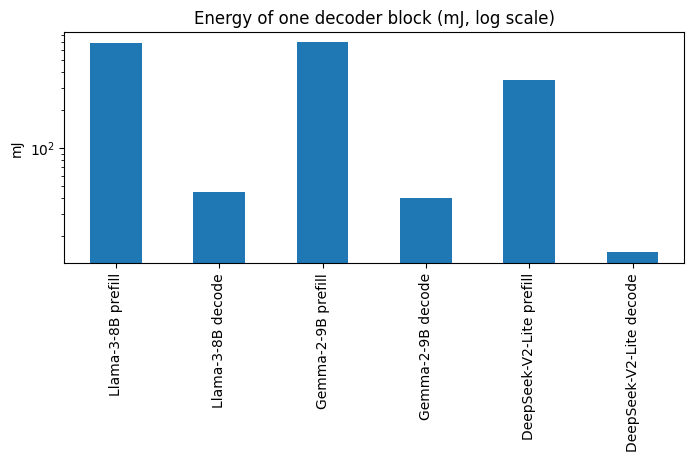

In [11]:
llm = pd.DataFrame([row(k, v) for k, v in reps.items() if "prefill" in k or "decode" in k])
display(llm.drop(columns=["total_pJ"]))
ax = llm.set_index("design / workload")["total_pJ"].div(1e9).plot.bar(figsize=(8, 3), legend=False, logy=True,
                                                                     title="Energy of one decoder block (mJ, log scale)")
ax.set_xlabel(""); ax.set_ylabel("mJ");

### 6.1 Prefill against decode: the same weights, 512 times less work

The Llama block in prefill costs 691 mJ for 512 tokens; in decode it costs
44 mJ for one token. Per token, decode is 33 times more expensive. The
reason is reuse, and you can read it off two counters.

In [12]:
pre, dec = reps["Llama-3-8B prefill"], reps["Llama-3-8B decode"]
def dram_rows(rep):
    return {r["label"]: r["pct"] for r in rep["dram_breakdown"]["rows"]}
pd.DataFrame([
    {"phase": "prefill (512 tokens)", "useful MACs": f"{pre['efficiency']['mac_ops']:.3g}", "DRAM %": pre["npu_dram_split"]["dram_pct"],
     "arrays %": round(sum(c["energy_pct"] for c in pre["components"] if c["name"].endswith(".pe")), 1),
     **{k: f"{v}%" for k, v in dram_rows(pre).items()}},
    {"phase": "decode (1 token)", "useful MACs": f"{dec['efficiency']['mac_ops']:.3g}", "DRAM %": dec["npu_dram_split"]["dram_pct"],
     "arrays %": round(sum(c["energy_pct"] for c in dec["components"] if c["name"].endswith(".pe")), 1),
     **{k: f"{v}%" for k, v in dram_rows(dec).items()}},
])

,phase,useful MACs,DRAM %,arrays %,Row activation (ACT+PRE),Transfer — read,Transfer — write,Refresh
0,prefill (512 tokens),1.14e+11,11.7,83.4,26.3%,62.3%,7.0%,4.5%
1,decode (1 token),2.23e+08,88.1,3.4,30.8%,64.2%,0.2%,4.9%


**Why DRAM takes over in decode.** Every GEMM of the block reads its whole
weight matrix from DRAM once. In prefill each weight is then used for 512
input rows; in decode it is used for one. The bytes from DRAM are the same
(the weights of one block, about 870 MB in float32), the MACs are 512 times
fewer, so the DRAM energy per MAC is 512 times higher. The arrays, which were
83% of prefill, are 3% of decode. The DRAM breakdown shows that most of the
decode DRAM energy is data transfer, and a third is row activation: a
matrix-vector product streams each row once with little row-buffer reuse.

**Why refresh appears.** Refresh energy is proportional to time, not to
work. Refresh is 5% of the DRAM energy in both phases, but DRAM is 88% of
the decode run and 12% of the prefill run, so refresh is 4% of the decode
energy and 0.5% of the prefill energy. Decode spends 3.8 M cycles on 222 M
MACs; the HBM refreshes all the while.

**What the arrays do in decode.** The occupancy of the GEMV kernels is
reported as 100%: TOGSim counts an array cycle as active only while input
rows stream through it, and a 1-row GEMV streams one row per weight tile.
The arrays are idle for the rest of the time, waiting for weights, and the
idle time costs leakage only (the `leak` column of the per-kernel table).
So the TPU-like NPU is not wasting PE energy in decode; it is waiting.

**What would change the picture.** Batching decode requests reuses each
weight across the batch and moves the ratio back toward prefill. A smaller
data type halves the DRAM bytes (section 7 shows what the hardware model
can and cannot do about that).

### 6.2 Dense against MoE: fewer MACs, more expensive MACs

DeepSeek-V2-Lite activates 6 of 64 experts per token, so its block has far
fewer MACs per token than the dense blocks. But each expert GEMM in prefill
has only 48 rows.

In [13]:
ex_d = example("pytorchsim/tpu_like_fp32/deepseek_v2_lite/prefill")
occ_d = occupancy_table(texts["DeepSeek-V2-Lite prefill"], kernel_names(ex_d))
wd = windows_df(reps["DeepSeek-V2-Lite prefill"]).set_index("window")
occ_d["cycles"] = [int(wd.loc[k, "cycles"]) for k in occ_d["kernel"]]
occ_d["energy"] = [wd.loc[k, "total"] for k in occ_d["kernel"]]
occ_d["pJ per useful MAC"] = [round(float(wd.loc[k, "total_pJ"]) / m, 1) for k, m in zip(occ_d["kernel"], occ_d["useful MACs"])]
display(occ_d)
display(window_components(reps["DeepSeek-V2-Lite prefill"], "8_experts_up_gate"))
display(window_components(reps["DeepSeek-V2-Lite prefill"], "1_q_proj"))

,kernel,useful MACs,active PE cycles,occupancy %,cycles,energy,pJ per useful MAC
0,1_q_proj,3221225472,3227041792,99.8,139312,1.83e+04 µJ,5.7
1,2_kv_a_proj,603979776,671088640,90.0,54389,3.84e+03 µJ,6.4
2,3_kv_b_proj,1073741824,1073741824,100.0,61383,6.45e+03 µJ,6.0
3,4_attn_qk,805306368,1073741824,75.0,100308,5.86e+03 µJ,7.3
4,5_attn_av,536870912,538361856,99.7,76224,3.74e+03 µJ,7.0
5,6_o_proj,2147483648,2147483648,100.0,101607,1.23e+04 µJ,5.7
6,7_router,67108864,134217728,50.0,16117,625 µJ,9.3
7,8_experts_up_gate,17716740096,17730322432,99.9,4625367,1.56e+05 µJ,8.8
8,9_experts_down,8858370048,8865415168,99.9,3164956,8.4e+04 µJ,9.5
9,10_shared_up_gate,5905580032,5905580032,100.0,226925,3.38e+04 µJ,5.7


,component,energy
0,core0.array0.pe,4.48e+04 µJ
1,core0.array0.w_reg,1.27e+03 µJ
2,core0.array1.pe,4.48e+04 µJ
3,core0.array1.w_reg,1.27e+03 µJ
4,core0.vmem,1.38e+03 µJ
5,core0.vpu_spad,64 µJ
6,core0.vrf,125 µJ
7,core0.vfu,8.29 µJ


,component,energy
0,core0.array0.pe,8.14e+03 µJ
1,core0.array0.w_reg,231 µJ
2,core0.array1.pe,8.14e+03 µJ
3,core0.array1.w_reg,231 µJ
4,core0.vmem,31.8 µJ
5,core0.vpu_spad,11.6 µJ
6,core0.vrf,19.4 µJ
7,core0.vfu,1.28 µJ


**Why the expert GEMMs cost 8.8 to 9.5 pJ per MAC against 5.7 pJ for the
dense projections, although the array is full in both.** A weight-stationary
array amortizes each weight tile over the input rows that stream through
it. The dense projections stream 512 rows per weight tile; an expert GEMM
streams 48. So per MAC, the expert kernels fetch about 10 times more weight
bytes from DRAM, move them through the NoC buffers and the VMEM, and load
them into the array. Compare the two component tables above: the `pe`
energy per MAC is the same (2.5 pJ per array), while `dram_chan` goes from
0.4 to 3.2 pJ per MAC and `vmem` and `icnt_buf` grow by a similar factor.
(The `w_reg` line does not move: it is dominated by the idle cost of
16 384 registers per cycle, not by the writes.) The two expert kernels are
69% of the block's energy and 85% of its cycles.

**Why the router is expensive.** N = 64 output columns fill half of the
128-column weight tile, so half of the active PE cycles are empty (the
occupancy table shows 50%). It is small in absolute terms.

**Why decode is the same story for all three.** In decode every GEMM is a
GEMV, dense or expert. The expert GEMMs then have 1 row each and the dense
ones have 1 row: there is no difference in reuse, and all three blocks land
near 200 pJ per useful MAC with DRAM at 87 to 88%.

### 6.3 Gemma against Llama: the same energy for fewer MACs

The Gemma block has 9% fewer MACs than the Llama block (hidden 3584 instead
of 4096) but costs the same in prefill, 696 against 691 mJ.

In [14]:
g, l = reps["Gemma-2-9B prefill"], reps["Llama-3-8B prefill"]
wg, wl = windows_df(g).set_index("window"), windows_df(l).set_index("window")
pairs = ["1_q_proj", "3_attn_qk", "6_ffn_up_gate", "7_ffn_down"]
pd.DataFrame([{"kernel": k, "Gemma cycles": int(wg.loc[k, "cycles"]), "Llama cycles": int(wl.loc[k, "cycles"]),
               "Gemma energy": wg.loc[k, "total"], "Llama energy": wl.loc[k, "total"]} for k in pairs])

,kernel,Gemma cycles,Llama cycles,Gemma energy,Llama energy
0,1_q_proj,411821,345779,4.36e+04 µJ,4.9e+04 µJ
1,3_attn_qk,100824,152117,6.87e+03 µJ,7.56e+03 µJ
2,6_ffn_up_gate,5575632,3267126,3.58e+05 µJ,3.6e+05 µJ
3,7_ffn_down,2691664,1716468,1.78e+05 µJ,1.74e+05 µJ


**Why the FFN costs more per MAC on Gemma.** Its hidden size 3584 is 28
tiles of 128 and the FFN width 14336 is 112 tiles; PyTorchSim's autotuner
picked a tiling for this shape that takes 1.7 times more cycles than
Llama's FFN for 0.9 times the MACs. More cycles with the arrays active at
the same occupancy means more weight reloads and more time for leakage and
refresh. This is a mapping effect, visible in the cycle column, not a
hardware one.

**Why DRAM is 19% instead of 12%.** Gemma's heads are 256 wide instead of
128, so the attention GEMMs move twice the key-value bytes per head, and
the longer FFN runs give the HBM more time to refresh. The attention
kernels cost 6.4 pJ per MAC against 7.0 on Llama, because the wider head
fills the 128-deep reduction of the array better.

**What the activation changes.** GeGLU needs a tanh, which is an SFU
operation like the exponent of SiLU; the `10_gelu_mul` kernel costs about
the same as Llama's `10_silu_mul`. The activation is 1.4% of the block
either way. (This kernel ran with PyTorchSim's functional mode off, because
tanh crashes its functional simulator; the folder README explains.)

## 7. The same runs with bf16 PEs

Notebook 1 changed the PE to bf16 by swapping `compound_components.yaml`.
The workload scripts take the same flag, so any run above can be re-priced
with the bf16 model. The simulator data stays float32; only the hardware
model changes.

In [15]:
ex = example("pytorchsim/tpu_like_fp32/llama3_8b/prefill")
text_bf16 = run(ex, "--compound-components", "../../../tpu_like_bf16/compound_components.yaml",
                "--report", "out_bf16/", log_name="console_bf16.txt")
rep_bf16 = report(ex, "out_bf16/report.json")
pd.DataFrame([row("Llama-3-8B prefill, fp32 PEs", reps["Llama-3-8B prefill"]),
              row("Llama-3-8B prefill, bf16 PEs", rep_bf16)]).drop(columns=["total_pJ"])

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC,cycles,pJ / FLOP
0,"Llama-3-8B prefill, fp32 PEs",6.91e+05 µJ,11.7,88.750,91.5 W,6.06,7092273,3.03 pJ/FLOP
1,"Llama-3-8B prefill, bf16 PEs",2.83e+05 µJ,28.5,77.842,37.5 W,2.48,7092273,1.24 pJ/FLOP


**Why the total falls by 2.4× while the PE energy falls by 3.2×.** The PE
energy per MAC goes from 5.05 to 1.56 pJ, as in notebook 1, and the weight
registers halve (16 bits). Everything else keeps its float32 cost: the
DRAM bytes, the VMEM and NoC traffic, the vector unit and its register
file. Those were 17% of the fp32 run and are now 29% of the bf16 run. This
is the usual lesson of a datapath change: the parts you did not change set
the floor.

**What the model cannot do here.** A real bf16 kernel would also move half
the bytes. NPUWattch charges the byte counts the simulator recorded, so the
DRAM and NoC lines are an upper bound for a bf16 kernel. The bf16 README
says the same.

## Messages you will see

**Every time.** The same WARNING lines as in notebook 1 (`NW-8212` SRAM
macro layout, `NW-6607` kernel-total split between the arrays, `NW-8111`
register-file width). The INFO lines `NW-6014` (window names from
`kernels.yaml`), `NW-6217` (gem5 counts scaled by the tile graph), and
`NW-6222` (useful MACs and array occupancy of each GEMM kernel) are the
ones this notebook reads its reasons from. In runs with non-MAC kernels,
`NW-6001` says that they use the data type of the MAC kernels.

**In some runs:**

| What you see | What it means | What to do |
| --- | --- | --- |
| `WARNING (NW-6201): <hash>: the kernel has no linalg.matmul ...` | A kernel without a GEMM (softmax, norm, activation, the layout kernels of a convolution) | Nothing. The window is marked `non_mac` and its vector and SFU work is charged |
| `WARNING (NW-6208): <hash>: the kernel has SFU operations and an unknown operand dtype ...` | A run with no MAC kernel at all (`softmax/`) | Nothing. The SFU is charged at fp32, which is what the simulator ran |
| `WARNING (NW-6002): The run has no MAC kernel, so non-MAC kernels use an fp32 datapath.` | The whole run has no GEMM (`softmax/`) | Nothing. The data type the simulator ran is fp32 |
| `WARNING (NW-6218): <hash>: no tile graph file (*_tog.py) ...` | The kernel directory lacks the tile graph, so the gem5 counts are scaled by the COMP counts of the log | Copy the `*_tog.py` of the kernel into `outputs/<hash>/` (the tutorial roots have it) |
| `WARNING (NW-6221): <hash>: the operator '...' is not known ...` | NPUWattch cannot count the useful MACs of this operator | Every active PE cycle is charged as a MAC; the PE energy is an upper bound |
| `WARNING (NW-6015): <log>: the log has no entry in kernels.yaml ...` | A kernel that the names file does not list | Add the entry, or ignore it: the window keeps its hash |

In [16]:
show_summary(texts["Llama-3-8B prefill"])

INFO (NW-1902): Message summary: 0 CRITICAL, 0 ERROR, 14 WARNING, 41 INFO.
    NW-6201   WARNING  x6
    NW-6208   WARNING  x3
    NW-6607   WARNING  x1
    NW-8111   WARNING  x1
    NW-8212   WARNING  x3


Next: `03_timeloop_eyeriss.ipynb`.